# Kristiansund bridge replanning


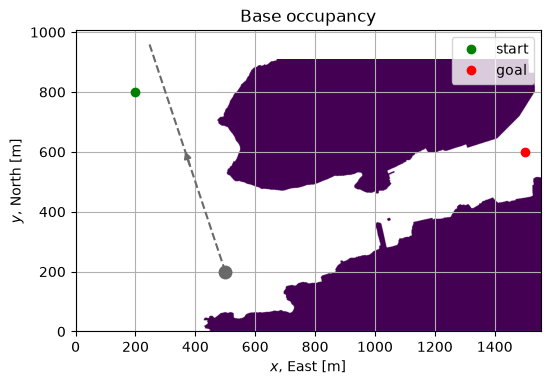

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cartoblobpy.graph import Graph

from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *

g = Graph()
g.load_from_yaml("../maps/kristiansund_bridge/map.yaml")
# g.goal = (1850.0, 1800.0)
g.start = (200.0, 800.0)
g.goal = (1500, 600.0)
obstacles = [
    # LinearDynamicObstacle.create(start_pose=(1450.0, 600.0), end_pose=(500.0, 250.0), velocity=3.0),
    LinearDynamicObstacle.create(start_pose=(500.0, 200.0), end_pose=(300.0, 800.0), velocity=2.0),
    # LinearDynamicObstacle.create(start_pose=(500.0, 700.0), end_pose=(100.0, 100.0), velocity=1.0),
    # LinearDynamicObstacle.create(start_pose=(1500.0, 1100.0), end_pose=(250.0, 1100.0), velocity=3.0),
    # LinearDynamicObstacle.create(start_pose=(2300.0, 1800.0), end_pose=(5400.0, 4000.0), velocity=5.0),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

In [2]:
from risk_informed_planner.config import Config
from risk_informed_planner.risk import cost_model
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
)
from risk_informed_planner.utils import Node

start = Node(g.start[0], g.start[1], 0)
goal = Node(g.goal[0], g.goal[1], -1)


In [3]:
import time

max_nodes = 1200
cfg = Config(
    X_LIMITS=(0, g.width),
    Y_LIMITS=(0, g.height),
    STEP_SIZE=50,
    GOAL_RADIUS=75,
    NEIGHBOR_RADIUS=150,
    MAX_NODES=max_nodes,
    # MAX_NEIGHBORS_RISK_RENEWAL=None,
    ALPHA=0.1,
    BETA=100.0,
    GAMMA=0.6,
    MAX_TURN_ANGLE=np.pi / 4.0,
    # RISK_CUTOFF=0.20,
    RISK_SAMPLE_SPACING=30.0,
    RISK_AGGREGATION="max"
)

min_depth = 6.0

# risk_model / path_planner are (re)built once per simulation step inside the
# receding-horizon loop below, since both the vessel's start position and the
# obstacles' poses change from step to step.
def build_planner(start_node: Node, current_obstacles) -> RiskAwareAngleCostRRTStarSearch:
    risk_model = DynamicRisk(
        max_distance_from_shore=150.0,
        lookahead_distance=150.0,
        graph=g,
        obstacles=current_obstacles,
        max_dcpa_for_collision_risk=50.0,
        max_tcpa_for_collision_risk=120.0,
        max_relative_velocity_for_collision_risk=6.0,
        grounding_depth_hard_limit=min_depth,
        desired_speed=3.0,
        cost_model=cost_model.NormalizedExpectedLoss(),

    )
    # cfg.RISK_CUTOFF=risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network) / 4.0

    path_planner = RiskAwareAngleCostRRTStarSearch(
        start=start_node,
        goal=goal,
        graph=g,
        cfg=cfg,
        risk_model=risk_model,
        # callback_functions=[],
        record_bbn_snapshots=True,
        min_depth=min_depth,
        free_check_method=RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.DEPTH_SAMPLING_OCCUPANCY_CHECKS
    )
    return path_planner, risk_model


In [4]:
from risk_informed_planner.visualization import *

def position_at_time(path, elapsed, speed):
    """Vessel position along ``path`` after ``elapsed`` seconds at ``speed``.

    Mirrors the logic ``plot_vessel_on_path_at_t`` uses to draw the
    "position at t" marker, so the vessel's next start position is exactly
    where that marker is plotted.
    """
    distance_traveled = 0.0
    for i in range(1, len(path)):
        segment_length = np.linalg.norm(
            np.array((path[i].x, path[i].y)) - np.array((path[i - 1].x, path[i - 1].y))
        )
        time_to_travel_segment = segment_length / speed
        if distance_traveled + time_to_travel_segment > elapsed:
            remaining_time = elapsed - distance_traveled
            ratio = remaining_time / time_to_travel_segment
            x = path[i - 1].x + ratio * (path[i].x - path[i - 1].x)
            y = path[i - 1].y + ratio * (path[i].y - path[i - 1].y)
            return (x, y)
        distance_traveled += time_to_travel_segment
    return (path[-1].x, path[-1].y)

def advance_obstacle(obs, elapsed):
    """Move a dynamic obstacle forward by ``elapsed`` seconds, re-anchoring
    its course to start (t=0) at its new pose so future ``.position(t)``
    calls are relative to this step again."""
    if isinstance(obs, LinearDynamicObstacle):
        x, y, yaw = obs.position(t=elapsed)
        return LinearDynamicObstacle(x, y, yaw, obs.velocity)
    return obs

N_STEPS = 3
save_dir = "plots/campaign"

current_start = (g.start[0], g.start[1])
current_obstacles = obstacles
step_results = []

for step in range(N_STEPS):
    start_node = Node(current_start[0], current_start[1], 0)
    path_planner, risk_model = build_planner(start_node, current_obstacles)

    start_time = time.perf_counter()
    nodes, path = path_planner()
    t_computation = time.perf_counter() - start_time
    print(f"[step {step:02d}] planning completed in {t_computation:.2f}s, "
          f"path length = {len(path) if path else 0}")

    save_prefix = f"step_{step:02d}_"
    plot_paper_panels(
        nodes=nodes,
        path=path,
        cfg=cfg,
        graph=g,
        obstacles=current_obstacles,
        t_computation=t_computation,
        speed=risk_model.desired_speed,
        metrics=("risk", "collision", "grounding"),
        modes=("heatmap",),
        vmin={"risk": 0.00, "collision": 0.05, "grounding": 0.25},
        vmax={'risk': 0.1, 'collision': 0.2, 'grounding': 0.4},
        latex=False,
        save_dir=save_dir,
        save_prefix=save_prefix,
        save_ext="png",
        legend=False,
    )
    plt.close('all')

    step_results.append(dict(
        step=step,
        start=current_start,
        obstacles=current_obstacles,
        nodes=nodes,
        path=path,
        t_computation=t_computation,
    ))

    if not path or len(path) < 2:
        print(f"[step {step:02d}] no path found, stopping simulation.")
        break

    if np.hypot(current_start[0] - g.goal[0], current_start[1] - g.goal[1]) <= cfg.GOAL_RADIUS:
        print(f"[step {step:02d}] goal reached, stopping simulation.")
        break

    # After the computation: advance the vessel and every obstacle by the
    # time it took to compute this step's plan, then use those as the next
    # experiment's start position and obstacle poses.
    current_start = position_at_time(path, t_computation, risk_model.desired_speed)
    current_obstacles = [advance_obstacle(o, t_computation) for o in current_obstacles]


Progress:   0%|          | 0/1200 [00:00<?, ?node/s]

[step 00] planning completed in 15.66s, path length = 19


Progress:   0%|          | 0/1200 [00:00<?, ?node/s]

[step 01] planning completed in 15.24s, path length = 21


Progress:   0%|          | 0/1200 [00:00<?, ?node/s]

[step 02] planning completed in 14.36s, path length = 19


In [5]:
from risk_informed_planner.experiment import PlannerRun

# Save the whole campaign (one PlannerRun per step) so replanning_campaign_figures.ipynb
# can plot it without re-running the simulation.
campaign_runs = [
    PlannerRun(
        nodes=r["nodes"],
        path=r["path"],
        cfg=cfg,
        graph=g,
        obstacles=r["obstacles"],  # obstacle poses at the start of this step
        t_computation=r["t_computation"],
        speed=risk_model.desired_speed,
        map_file="../maps/kristiansund_bridge/map.yaml",  # map is re-read from here on load
        metadata=dict(step=r["step"], start=r["start"]),
    )
    for r in step_results
]
campaign_file = PlannerRun.save_many(campaign_runs, "results/campaign.pkl")
print(f"saved {len(campaign_runs)} steps to {campaign_file.resolve()}")

saved 3 steps to /Users/emircem/Library/CloudStorage/OneDrive-NTNU/Projects/RiskAwareRRTPlanner/risk-informed-planner/notebooks/experiments/results/campaign.pkl


In [6]:
from risk_informed_planner.visualization import *

# Quick sanity-check overview (heuristic/risk/cost + BBN collision/grounding)
# for the final simulated step.

# last = step_results[0]

save_dir = "plots/explainability"

for index, last in enumerate(step_results):


    # fig, ax = plt.subplots(3, 3, figsize=(22, 16))

    # axes = plot_matrix(
    #     nodes=last["nodes"],
    #     obstacles=last["obstacles"],
    #     path=last["path"],
    #     cfg=cfg,
    #     graph=g,
    #     ax=ax,
    #     t_computation=last["t_computation"],
    #     speed=risk_model.desired_speed,
    # )
    # plt.savefig(f"plots/campaign/step_{last['step']:02d}_overview.pdf")

    save_prefix = f"steps_{index:04d}_"
    plot_paper_panels(
        nodes=last["nodes"],
        path=last["path"],
        cfg=cfg,
        graph=g,
        obstacles=obstacles,
        t_computation=last["t_computation"],
        speed=risk_model.desired_speed,
        metrics=("risk", "collision", "grounding",),
        modes=("heatmap",),
        vmin={"risk": 0.00, "collision": 0.05, "grounding": 0.25},
        vmax={'risk': 0.1, 'collision': 0.2, 'grounding': 0.4},
        latex=False,
        save_dir=save_dir,
        save_prefix=save_prefix,
        save_ext="png"
    )
    plt.close('all')
